In [1]:
import pandas as pd

In [2]:
Customer = pd.read_excel("Customers_dataset.xlsx")
Customer.head()

,customer_id,customer_zip_code,gender,age_group,customer_segment
0,C00001,690511,Female,36-45,Loyal
1,C00002,509152,Male,26-35,New
2,C00003,477335,Male,26-35,Loyal
3,C00004,140413,Female,65+,Loyal
4,C00005,700009,Male,26-35,Loyal


In [3]:
Orders = pd.read_excel("Orders_Dataset_Cleaned.xlsx")
Orders.head()

,order_id,customer_id,order_status,payment_type,order_purchase_timestamp,order_approved_at,order_delivered_shipping_date,order_delivered_customer_date,order_estimated_delivery_date
0,O00001,C60210,delivered,Net Banking,2024-11-04,2024-11-04,2024-12-01,2025-03-04,2025-01-03
1,O00002,C01893,delivered,Net Banking,2023-09-01,2023-09-01,2023-10-01,2023-10-05,2023-10-31
2,O00003,C19454,cancelled,UPI,2021-08-06,2021-08-06,2021-08-16,2021-08-19,2021-08-17
3,O00004,C67148,delivered,UPI,2025-07-07,2025-07-07,2025-10-06,2025-10-12,2025-07-12
4,O00005,C56280,delivered,Net Banking,2024-03-30,2024-03-30,2024-03-31,2024-04-04,2024-04-07


In [4]:
Order_item = pd.read_excel("Order_items_dataset.xlsx")
Order_item.head()

,order_item_id,order_id,quantity,product_id,unit_price,discount(%),shipping_cost
0,OI000001,O00001,1,P28355,7020,6.54,713.72
1,OI000002,O00002,1,P04408,7590,20.56,1212.02
2,OI000003,O00002,2,P14887,14360,24.67,1478.39
3,OI000004,O00003,2,P02014,1530,12.06,155.12
4,OI000005,O00003,1,P27255,1560,10.51,188.03


In [5]:
Product = pd.read_excel("Products_dataset.xlsx")
Product.head()

,product_id,Category_name,sub_category_name,product_weight_g,brand,cost_price,selling_price,stock_availability
0,P00001,perfumery,Fragrances,225,Nivea,2200,2860,In Stock
1,P00002,art,General Merchandise,1000,Generic Global,110,140,In Stock
2,P00003,sports_leisure,General Merchandise,154,Generic Indian,14680,17170,In Stock
3,P00004,baby,Collectibles,371,Generic Indian,3890,4920,In Stock
4,P00005,housewares,Novelty Items,625,Generic Indian,12590,16220,In Stock


## Objective - 4

### Task 1 :- Analyze sales distribution, revenue trends, and customer purchasing patterns using visualizations.

### 1. Sales Distribution by Product Category (Bar Chart)

In [36]:
import matplotlib.pyplot as plt

sales = Order_item.merge(Product, on='product_id')

sales.head()

,order_item_id,order_id,quantity,product_id,unit_price,discount(%),shipping_cost,Category_name,sub_category_name,product_weight_g,brand,cost_price,selling_price,stock_availability
0,OI000001,O00001,1,P28355,7020,6.54,713.72,sports_leisure,Novelty Items,1325,Generic Indian,5330,7020,In Stock
1,OI000002,O00002,1,P04408,7590,20.56,1212.02,sports_leisure,Novelty Items,24700,Generic Indian,6190,7590,In Stock
2,OI000003,O00002,2,P14887,14360,24.67,1478.39,health_beauty,Gifts,400,Generic Indian,11720,14360,In Stock
3,OI000004,O00003,2,P02014,1530,12.06,155.12,garden_tools,General Merchandise,5400,Generic Indian,1300,1530,In Stock
4,OI000005,O00003,1,P27255,1560,10.51,188.03,toys,Collectibles,650,Generic Indian,1300,1560,In Stock


In [37]:
category_sales = sales.groupby('Category_name')['quantity'].sum().sort_values(ascending=False).head(10)
print(category_sales)

Category_name
bed_bath_table              18969
sports_leisure              18186
health_beauty               15000
housewares                  14627
perfumery                   11682
stationery                  11241
fashion_bags_accessories    10920
auto                         9616
toys                         9304
watches_gifts                8312
Name: quantity, dtype: int64


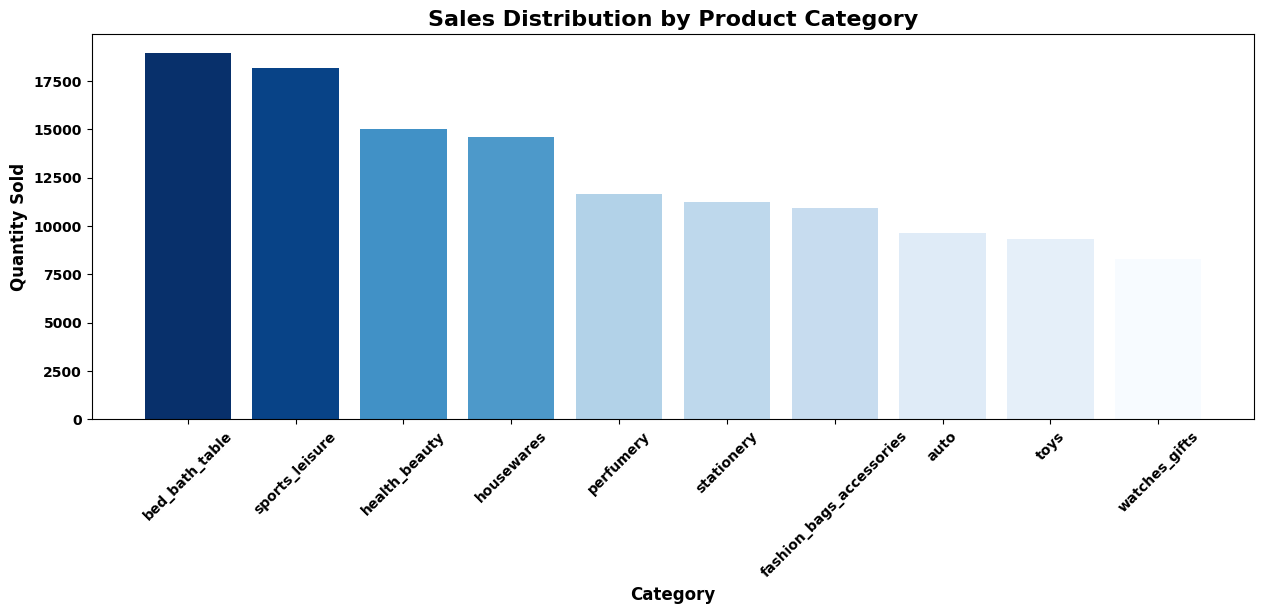

In [42]:
import matplotlib.pyplot as plt
import numpy as np

values = category_sales.values
norm = plt.Normalize(values.min(), values.max())
colors = plt.cm.Blues(norm(values))

plt.figure(figsize=(15,5))
plt.bar(category_sales.index, values, color=colors)

# Bold Title
plt.title("Sales Distribution by Product Category",
          fontsize=16, fontweight='bold')

# Bold Axis Labels
plt.xlabel("Category", fontsize=12, fontweight='bold')
plt.ylabel("Quantity Sold", fontsize=12, fontweight='bold')

# Bold X and Y Tick Labels
plt.xticks(rotation=45, fontsize=10, fontweight='bold')
plt.yticks(fontsize=10, fontweight='bold')

plt.show()

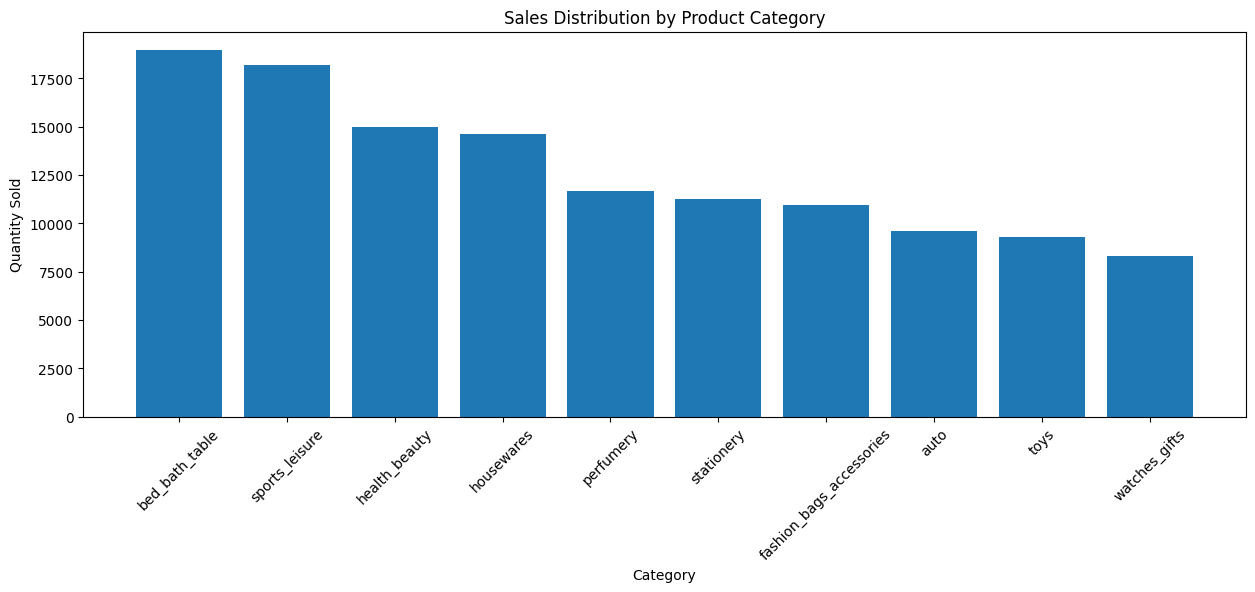

In [40]:
plt.figure(figsize=(15,5))
plt.bar(category_sales.index, category_sales.values)
plt.xticks(rotation=45)
plt.title("Sales Distribution by Product Category")
plt.xlabel("Category")
plt.ylabel("Quantity Sold")
plt.show()

### 2. Monthly Revenue Trend (Line Chart)

In [9]:
Orders['order_purchase_timestamp'] = pd.to_datetime(Orders['order_purchase_timestamp'])

revenue = Orders.merge(Order_item, on='order_id')

revenue['month'] = revenue['order_purchase_timestamp'].dt.to_period('M')

monthly_revenue = revenue.groupby('month')['unit_price'].sum()

print(monthly_revenue.head())

month
2021-04    11798580
2021-05    12808240
2021-06    11490190
2021-07    13171990
2021-08    20219380
Freq: M, Name: unit_price, dtype: int64


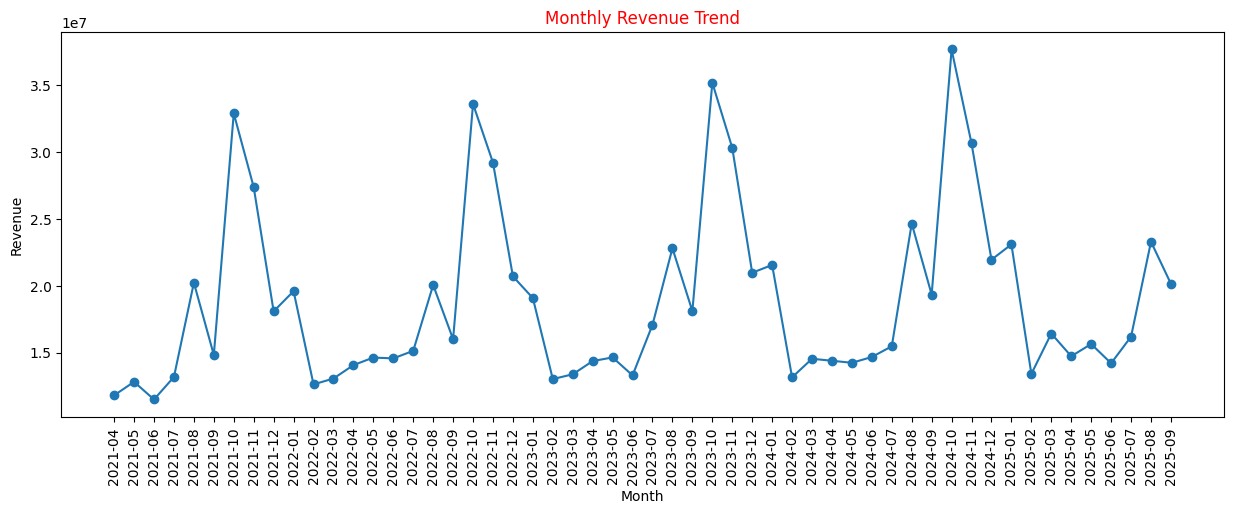

In [10]:
plt.figure(figsize=(15,5))
plt.plot(monthly_revenue.index.astype(str), monthly_revenue.values, marker='o')
plt.xticks(rotation=90)
plt.title("Monthly Revenue Trend",color = 'red')
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.show()

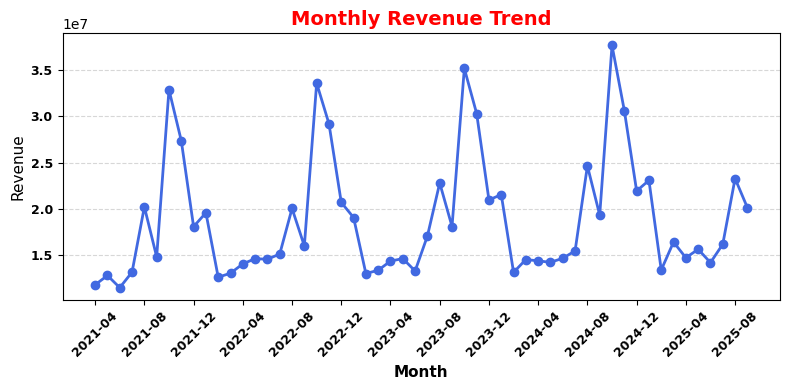

In [47]:
plt.figure(figsize=(8,4))

plt.plot(
    monthly_revenue.index.astype(str),
    monthly_revenue.values,
    marker='o',
    linewidth=2,
    color='royalblue'
)

# Show labels every 4 months
plt.xticks(
    ticks=range(0, len(monthly_revenue), 4),
    labels=monthly_revenue.index.astype(str)[::4],
    rotation=45,
    fontsize=9,
    fontweight='bold'
)

plt.yticks(fontsize=9, fontweight='bold')

plt.title("Monthly Revenue Trend", fontsize=14, fontweight='bold',color = 'red')
plt.xlabel("Month", fontsize=11, fontweight='bold')
plt.ylabel("Revenue", fontsize=11)

plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

### 3. Customer Purchasing Pattern by Segment (Bar Chart)

In [11]:
purchase = Customer.merge(Orders, on='customer_id')

customer_orders = purchase.groupby('customer_segment')['order_id'].count()

print(customer_orders.head())

customer_segment
Loyal        14718
New          50121
Returning    35160
Name: order_id, dtype: int64


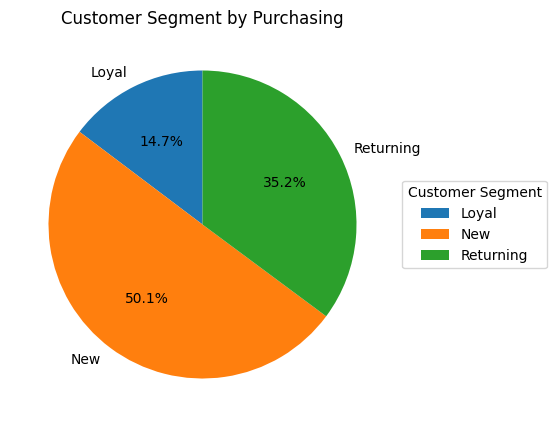

In [12]:
plt.figure(figsize=(10,5))

plt.pie(customer_orders.values,labels=customer_orders.index,
        autopct='%1.1f%%', startangle=90)
plt.title("Customer Segment by Purchasing")
plt.legend(title="Customer Segment",loc="center left",bbox_to_anchor=(1, 0.5))
plt.show()

### 4. Revenue by Brand (Top 10) (Bar Chart)

In [13]:
brand_sales = Order_item.merge(Product, on='product_id')

brand_sales['revenue'] = (
    brand_sales['unit_price'] * brand_sales['quantity'])

print(brand_sales.head())

  order_item_id order_id  quantity product_id  unit_price  discount(%)  \
0      OI000001   O00001         1     P28355        7020         6.54   
1      OI000002   O00002         1     P04408        7590        20.56   
2      OI000003   O00002         2     P14887       14360        24.67   
3      OI000004   O00003         2     P02014        1530        12.06   
4      OI000005   O00003         1     P27255        1560        10.51   

   shipping_cost   Category_name    sub_category_name  product_weight_g  \
0         713.72  sports_leisure        Novelty Items              1325   
1        1212.02  sports_leisure        Novelty Items             24700   
2        1478.39   health_beauty                Gifts               400   
3         155.12    garden_tools  General Merchandise              5400   
4         188.03            toys         Collectibles               650   

            brand  cost_price  selling_price stock_availability  revenue  
0  Generic Indian        5330

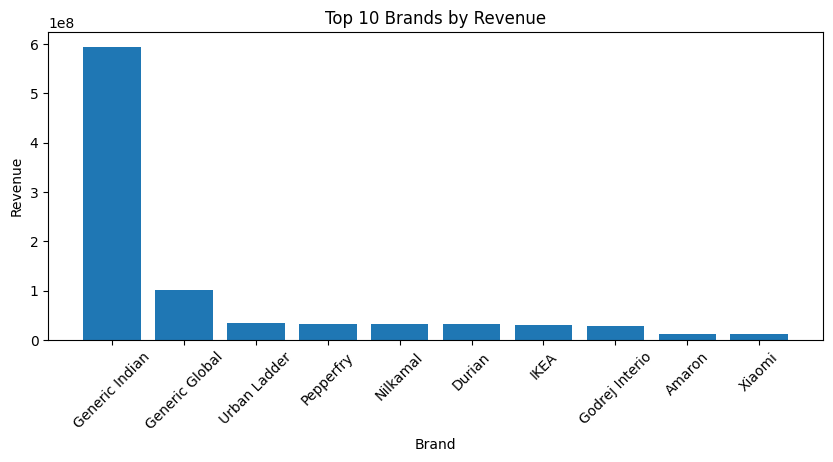

In [14]:
top_brands = brand_sales.groupby('brand')['revenue'].sum().sort_values(ascending=False).head(10)

plt.figure(figsize=(10,4))
plt.bar(top_brands.index, top_brands.values)
plt.xticks(rotation=45)
plt.title("Top 10 Brands by Revenue")
plt.xlabel("Brand")
plt.ylabel("Revenue")
plt.show()

### Task 2 :- Explore relationships between price, discounts, shipping costs, and order value using correlation analysis.

In [15]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [16]:
df = pd.merge(Order_item, Product, on='product_id', how='inner')

df['discount_amount'] = df['unit_price'] * (df['discount(%)'] / 100)

print(df.head())

  order_item_id order_id  quantity product_id  unit_price  discount(%)  \
0      OI000001   O00001         1     P28355        7020         6.54   
1      OI000002   O00002         1     P04408        7590        20.56   
2      OI000003   O00002         2     P14887       14360        24.67   
3      OI000004   O00003         2     P02014        1530        12.06   
4      OI000005   O00003         1     P27255        1560        10.51   

   shipping_cost   Category_name    sub_category_name  product_weight_g  \
0         713.72  sports_leisure        Novelty Items              1325   
1        1212.02  sports_leisure        Novelty Items             24700   
2        1478.39   health_beauty                Gifts               400   
3         155.12    garden_tools  General Merchandise              5400   
4         188.03            toys         Collectibles               650   

            brand  cost_price  selling_price stock_availability  \
0  Generic Indian        5330        

In [17]:
df['order_value'] = ((df['unit_price'] - df['discount_amount']) * df['quantity']+ df['shipping_cost'])
print(df.head())

  order_item_id order_id  quantity product_id  unit_price  discount(%)  \
0      OI000001   O00001         1     P28355        7020         6.54   
1      OI000002   O00002         1     P04408        7590        20.56   
2      OI000003   O00002         2     P14887       14360        24.67   
3      OI000004   O00003         2     P02014        1530        12.06   
4      OI000005   O00003         1     P27255        1560        10.51   

   shipping_cost   Category_name    sub_category_name  product_weight_g  \
0         713.72  sports_leisure        Novelty Items              1325   
1        1212.02  sports_leisure        Novelty Items             24700   
2        1478.39   health_beauty                Gifts               400   
3         155.12    garden_tools  General Merchandise              5400   
4         188.03            toys         Collectibles               650   

            brand  cost_price  selling_price stock_availability  \
0  Generic Indian        5330        

In [18]:
corr_data = df[['unit_price','discount(%)',
                'shipping_cost','order_value']]

correlation = corr_data.corr()

print(correlation)

               unit_price  discount(%)  shipping_cost  order_value
unit_price       1.000000     0.401575       0.935218     0.963865
discount(%)      0.401575     1.000000       0.356791     0.325618
shipping_cost    0.935218     0.356791       1.000000     0.916086
order_value      0.963865     0.325618       0.916086     1.000000


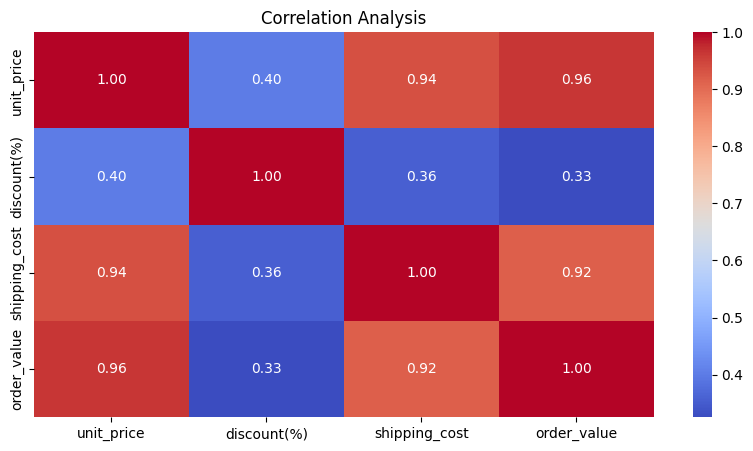

In [19]:
plt.figure(figsize=(10,5))
sns.heatmap(correlation, annot=True, cmap='coolwarm',fmt='.2f')
plt.title("Correlation Analysis")
plt.show()

### Task 3 - Identify outliers and patterns in customer orders, product prices, and delivery performance.

#### 1. Detect Outliers in Product Prices (Box Plot)

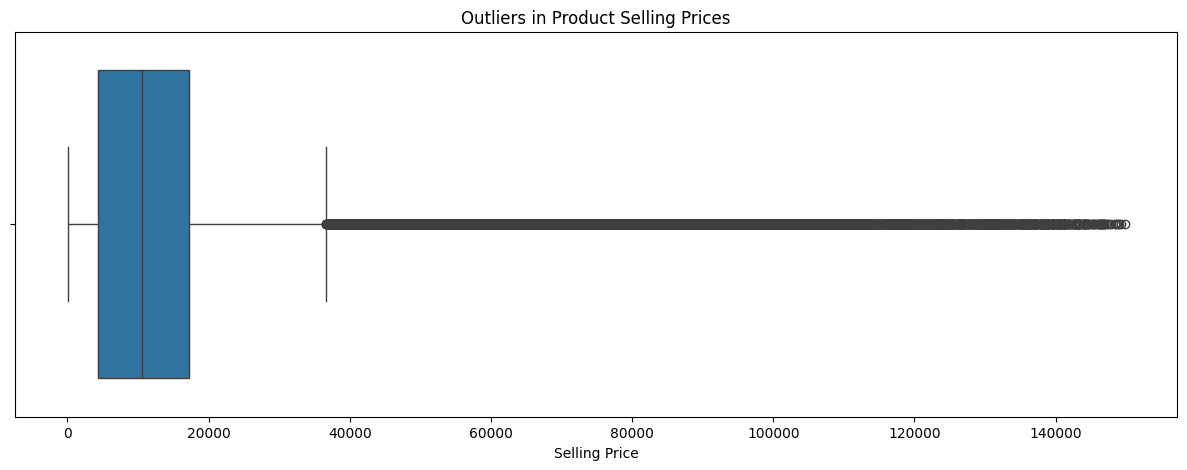

In [20]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(15,5))
sns.boxplot(x=Product['selling_price'])
plt.title("Outliers in Product Selling Prices")
plt.xlabel("Selling Price")
plt.show()

#### 2. Detect Outliers in Customer Order Values (Box Plot)

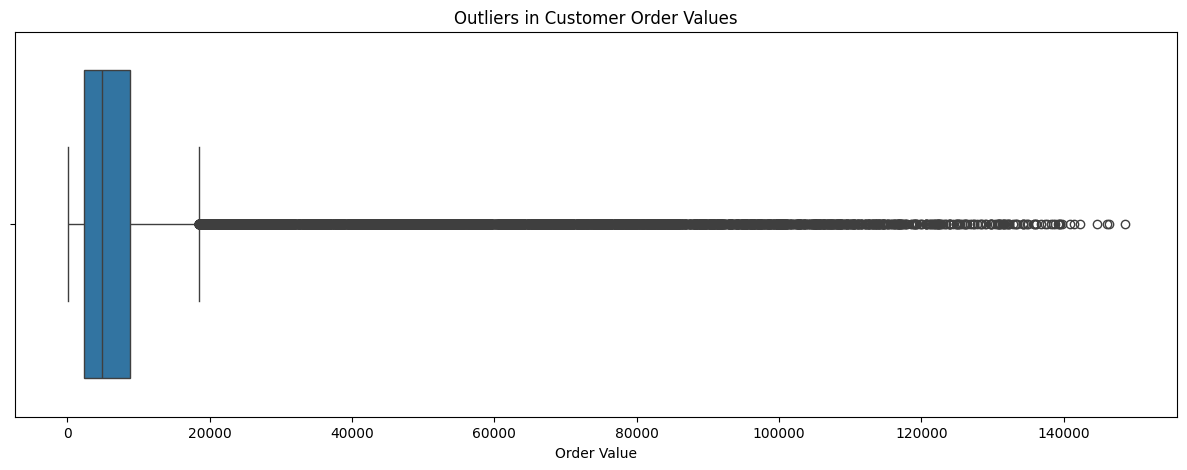

In [21]:
df = Order_item.copy()

df['order_value'] = ((df['unit_price'] - (df['unit_price'] * df['discount(%)'] / 100))
                      * df['quantity'] + df['shipping_cost'])

plt.figure(figsize=(15,5))
sns.boxplot(x=df['order_value'])
plt.title("Outliers in Customer Order Values")
plt.xlabel("Order Value")
plt.show()

#### 3. Analyze Delivery Performance (Histogram)

In [22]:
Orders['order_purchase_timestamp'] = pd.to_datetime(
    Orders['order_purchase_timestamp'])

print(Orders.head())

  order_id customer_id order_status payment_type order_purchase_timestamp  \
0   O00001      C60210    delivered  Net Banking               2024-11-04   
1   O00002      C01893    delivered  Net Banking               2023-09-01   
2   O00003      C19454    cancelled          UPI               2021-08-06   
3   O00004      C67148    delivered          UPI               2025-07-07   
4   O00005      C56280    delivered  Net Banking               2024-03-30   

  order_approved_at order_delivered_shipping_date  \
0        2024-11-04                    2024-12-01   
1        2023-09-01                    2023-10-01   
2        2021-08-06                    2021-08-16   
3        2025-07-07                    2025-10-06   
4        2024-03-30                    2024-03-31   

  order_delivered_customer_date order_estimated_delivery_date  
0                    2025-03-04                    2025-01-03  
1                    2023-10-05                    2023-10-31  
2                    2021-

In [23]:
Orders['order_delivered_customer_date'] = pd.to_datetime(
    Orders['order_delivered_customer_date'])

print(Orders.head())

  order_id customer_id order_status payment_type order_purchase_timestamp  \
0   O00001      C60210    delivered  Net Banking               2024-11-04   
1   O00002      C01893    delivered  Net Banking               2023-09-01   
2   O00003      C19454    cancelled          UPI               2021-08-06   
3   O00004      C67148    delivered          UPI               2025-07-07   
4   O00005      C56280    delivered  Net Banking               2024-03-30   

  order_approved_at order_delivered_shipping_date  \
0        2024-11-04                    2024-12-01   
1        2023-09-01                    2023-10-01   
2        2021-08-06                    2021-08-16   
3        2025-07-07                    2025-10-06   
4        2024-03-30                    2024-03-31   

  order_delivered_customer_date order_estimated_delivery_date  
0                    2025-03-04                    2025-01-03  
1                    2023-10-05                    2023-10-31  
2                    2021-

In [24]:
Orders['delivery_days'] = (Orders['order_delivered_customer_date'] - Orders['order_purchase_timestamp']).dt.days

print(Orders.head())

  order_id customer_id order_status payment_type order_purchase_timestamp  \
0   O00001      C60210    delivered  Net Banking               2024-11-04   
1   O00002      C01893    delivered  Net Banking               2023-09-01   
2   O00003      C19454    cancelled          UPI               2021-08-06   
3   O00004      C67148    delivered          UPI               2025-07-07   
4   O00005      C56280    delivered  Net Banking               2024-03-30   

  order_approved_at order_delivered_shipping_date  \
0        2024-11-04                    2024-12-01   
1        2023-09-01                    2023-10-01   
2        2021-08-06                    2021-08-16   
3        2025-07-07                    2025-10-06   
4        2024-03-30                    2024-03-31   

  order_delivered_customer_date order_estimated_delivery_date  delivery_days  
0                    2025-03-04                    2025-01-03            120  
1                    2023-10-05                    2023-10-3

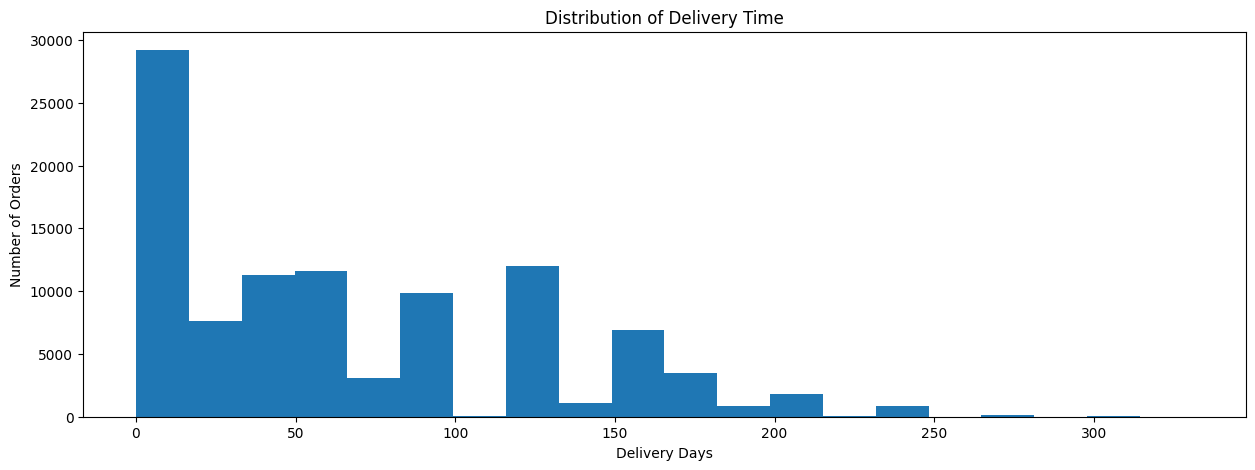

In [25]:
plt.figure(figsize=(15,5))
plt.hist(Orders['delivery_days'], bins=20)

plt.title("Distribution of Delivery Time")
plt.xlabel("Delivery Days")
plt.ylabel("Number of Orders")
plt.show()

#### 4. Relationship Between Product Price and Order Value (Scatter Plot)

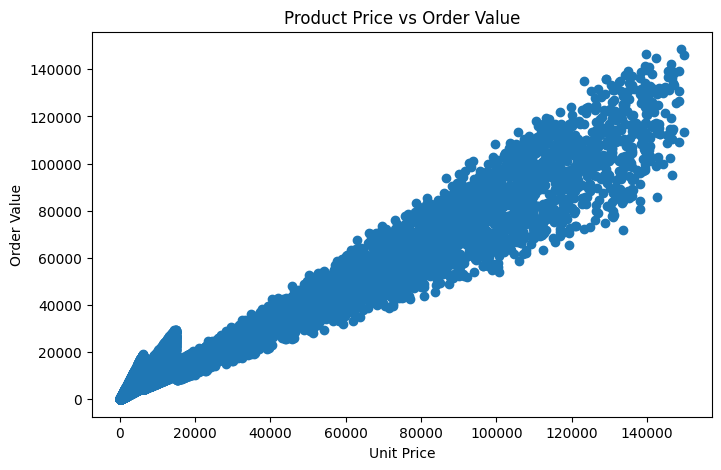

In [26]:
plt.figure(figsize=(8,5))
plt.scatter(df['unit_price'],df['order_value'])
plt.title("Product Price vs Order Value")
plt.xlabel("Unit Price")
plt.ylabel("Order Value")
plt.show()

### Task 4 - Visualize customer demographics, product categories, and regional sales trends to generate actionable business insights.

#### 1. Customer Demographics by Gender (Pie Chart)

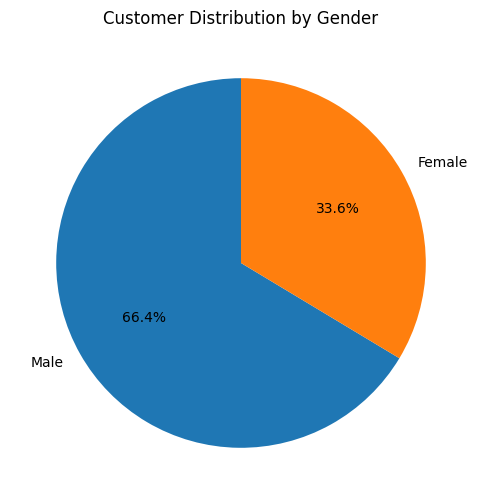

In [27]:
import matplotlib.pyplot as plt

gender_count = Customer['gender'].value_counts()

plt.figure(figsize=(6,6))
plt.pie(gender_count.values,labels=gender_count.index, autopct='%1.1f%%', startangle=90)
plt.title("Customer Distribution by Gender")
plt.show()

#### 2. Customer Demographics by Age Group (Bar Chart)

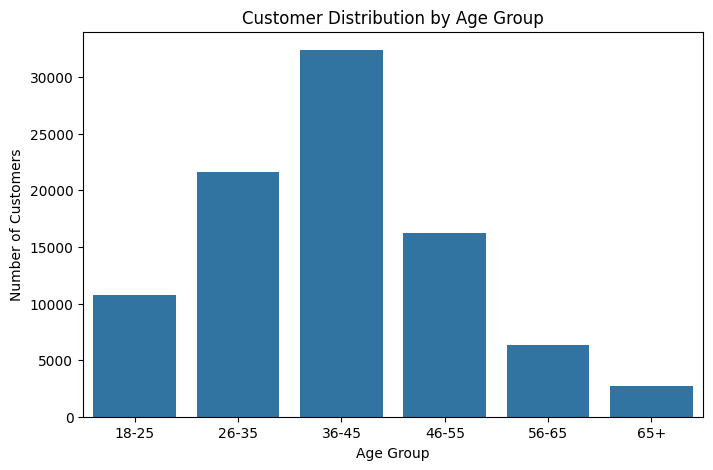

In [28]:
import seaborn as sns
import matplotlib.pyplot as plt

age_group = Customer['age_group'].value_counts().sort_index()

plt.figure(figsize=(8,5))
sns.barplot(x=age_group.index, y=age_group.values)
plt.title("Customer Distribution by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Customers")
plt.show()

#### 3. Product Category Sales (Top 10) (Bar Chart)

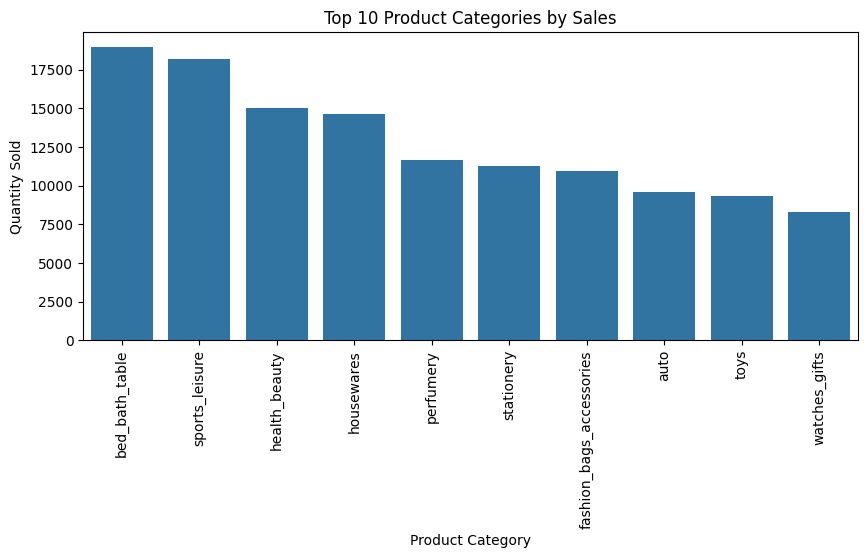

In [29]:
sales = Order_item.merge(Product, on='product_id')

category_sales = (sales.groupby('Category_name')['quantity'].sum().sort_values(ascending=False).head(10))

plt.figure(figsize=(10,4))
sns.barplot(x=category_sales.index, y=category_sales.values)
plt.xticks(rotation=90)
plt.title("Top 10 Product Categories by Sales")
plt.xlabel("Product Category")
plt.ylabel("Quantity Sold")
plt.show()

In [30]:
Location = pd.read_excel("Location_Dataset_Cleaned.xlsx")
Location.head()

,geolocation_zip_code,geolocation_city,geolocation_state,geolocation_lat,geolocation_lng,region
0,744301,Sawai,Andaman & Nicobar Islands,7.5166,93.6031,East
1,744301,Mus,Andaman & Nicobar Islands,9.2333,92.7833,East
2,744301,Kakana,Andaman & Nicobar Islands,9.1167,92.8000,East
3,744301,Carnicobar,Andaman & Nicobar Islands,9.1833,92.7667,East
4,744301,Lapathy,Andaman & Nicobar Islands,9.1833,92.7667,East


#### 4. Regional Sales Trend (Bar Chart)

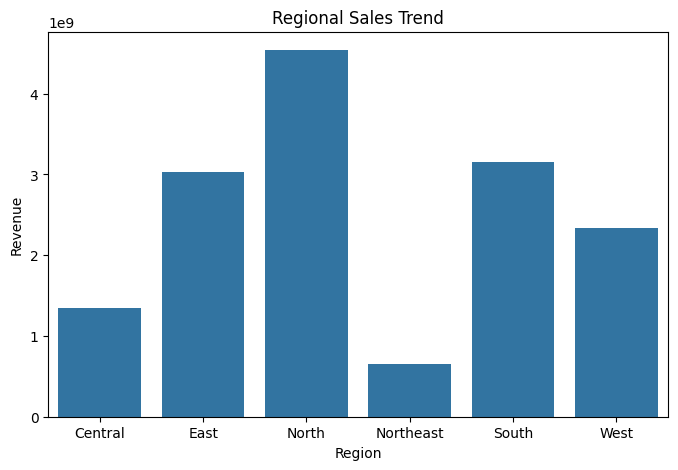

In [31]:
sales = (Orders.merge(Customer, on='customer_id').merge(Location,left_on='customer_zip_code',
                                                        right_on='geolocation_zip_code').merge(Order_item, on='order_id'))

sales['revenue'] = sales['unit_price'] * sales['quantity']

regional_sales = sales.groupby('region')['revenue'].sum()

plt.figure(figsize=(8,5))
sns.barplot(x=regional_sales.index, y=regional_sales.values)
plt.title("Regional Sales Trend")
plt.xlabel("Region")
plt.ylabel("Revenue")
plt.show()

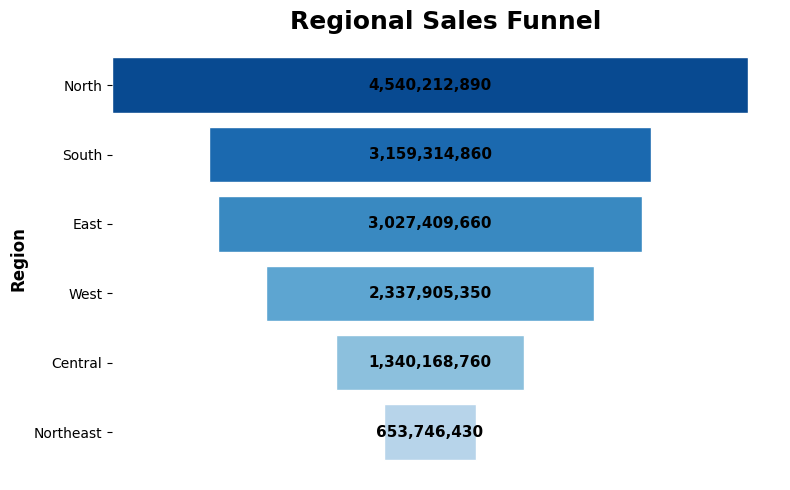

In [49]:
import matplotlib.pyplot as plt
import numpy as np

# Sort from highest to lowest
regional_sales = regional_sales.sort_values(ascending=False)

labels = regional_sales.index
values = regional_sales.values

# Center the bars
left = (values.max() - values) / 2

# Gradient colors
colors = plt.cm.Blues(np.linspace(0.9, 0.3, len(values)))

plt.figure(figsize=(8,5))

bars = plt.barh(
    labels,
    values,
    left=left,
    color=colors,
    edgecolor='white'
)

# Highest value at bottom (like your image)
plt.gca().invert_yaxis()

# Value labels
for bar, value in zip(bars, values):
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_y() + bar.get_height()/2,
        f'{value:,.0f}',
        ha='center',
        va='center',
        fontsize=11,
        fontweight='bold',
        color='black'
    )

plt.title("Regional Sales Funnel", fontsize=18, fontweight='bold')
plt.ylabel("Region", fontsize=12, fontweight='bold')

# Hide x-axis
plt.xticks([])
plt.box(False)

plt.tight_layout()
plt.show()

In [32]:
Customer.shape

(90000, 5)

In [33]:
Orders.shape

(99999, 10)

In [34]:
Order_item.shape

(150000, 7)

In [35]:
Location.shape

(155545, 6)